# Forecasting Groundwater-Level Changes Across India Using PySpark and Machine Learning

## Project Overview

This project analyses groundwater-level observations reported across India using Apache PySpark and machine-learning techniques.

The study uses the Central Ground Water Board (CGWB) dataset to examine spatial patterns, temporal coverage and station-level observations. It also investigates the feasibility of predicting subsequent groundwater-level observations using historical measurements and geographical features.

## Research Objectives

1. Examine the spatial and temporal distribution of groundwater-level observations across India.
2. Assess data quality, station coverage and temporal consistency.
3. Identify geographical and temporal patterns in recorded groundwater levels.
4. Develop and evaluate machine-learning models for predicting subsequent observations.
5. Compare model performance using RMSE, MAE and R².

## Dataset

**Source:** Central Ground Water Board (CGWB), India Data Portal

**Period in uploaded dataset:** 2013–March 2023

**Initial dataset size:** 550,850 records and 14 columns.

## Technology Stack

- Apache PySpark
- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- PySpark MLlib

## Research Scope

The analysis is based on the records and reporting coverage available in the supplied dataset. Changes in observation coverage will be considered when interpreting temporal and geographical patterns.

## 2. Environment Setup and Libraries

In [1]:

# Install PySpark
!pip install pyspark -q

# Import required libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.sql.types import *

from google.colab import files

# Keep notebook output clean
warnings.filterwarnings("ignore")

# Initialise Spark
spark = (
    SparkSession.builder
    .appName("India_Groundwater_Analytics")
    .master("local[*]")
    .getOrCreate()
)

print("Environment initialized successfully.")
print("PySpark version:", spark.version)


Environment initialized successfully.
PySpark version: 4.0.5


## 3. Dataset Loading

In [2]:

# Upload the original CGWB dataset
uploaded = files.upload()

# Get the uploaded CSV filename
csv_path = next(iter(uploaded.keys()))

# Load the CSV into a Spark DataFrame
df = (
    spark.read
    .option("header", True)
    .option("inferSchema", True)
    .option("dateFormat", "yyyy-MM-dd")
    .option("mode", "PERMISSIVE")
    .csv(csv_path)
)

print("Dataset loaded successfully.")
print("Source file:", csv_path)
print("Total records:", df.count())
print("Total columns:", len(df.columns))


Saving cgwb-changes-in-depth-to-water-level (1).csv to cgwb-changes-in-depth-to-water-level (1).csv
Dataset loaded successfully.
Source file: cgwb-changes-in-depth-to-water-level (1).csv
Total records: 550850
Total columns: 14


## 4. Dataset Structure and Initial Inspection

In [3]:

# Display column names and data types
print("Dataset Schema:")
df.printSchema()

# Display the first five records
print("Sample Records:")
df.show(5, truncate=False)

# Check dataset dimensions
print("Rows:", df.count())
print("Columns:", len(df.columns))


Dataset Schema:
root
 |-- id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- state_name: string (nullable = true)
 |-- state_code: integer (nullable = true)
 |-- district_name: string (nullable = true)
 |-- district_code: integer (nullable = true)
 |-- station_name: string (nullable = true)
 |-- latitude: double (nullable = true)
 |-- longitude: double (nullable = true)
 |-- basin: string (nullable = true)
 |-- sub_basin: string (nullable = true)
 |-- source: string (nullable = true)
 |-- currentlevel: double (nullable = true)
 |-- level_diff: double (nullable = true)

Sample Records:
+---+----------+---------------------------+----------+------------------------+-------------+------------+--------+---------+--------------------------------------------------+--------------------------------------------+------+------------+----------+
|id |date      |state_name                 |state_code|district_name           |district_code|station_name|latitude|longitude|basin     

## 5. Data Quality Assessment

In [4]:

# 1. Check missing values in every column
missing_expr = [
    F.sum(
        F.when(
            F.col(c).isNull() | (F.trim(F.col(c).cast("string")) == ""),
            1
        ).otherwise(0)
    ).alias(c)
    for c in df.columns
]

missing_values = df.agg(*missing_expr)
print("Missing values by column:")
missing_values.show(truncate=False)

# 2. Check exact duplicate records
duplicate_count = df.count() - df.dropDuplicates().count()
print("Exact duplicate records:", duplicate_count)

# 3. Check dataset coverage
print("Date coverage:")
df.select(
    F.min("date").alias("First observation"),
    F.max("date").alias("Last observation")
).show()

# 4. Check geographical coverage
print("Geographical coverage:")
df.agg(
    F.countDistinct("state_name").alias("States/UTs"),
    F.countDistinct(
        F.concat_ws("_", "state_name", "district_name")
    ).alias("State-District combinations"),
    F.countDistinct("station_name").alias("Unique station names")
).show()

# 5. Numerical summary
print("Numerical variable summary:")
df.select("currentlevel", "level_diff").describe().show()

# 6. Check invalid numerical values
print("Invalid numerical values:")
df.select(
    F.sum(F.when(F.col("currentlevel") < 0, 1).otherwise(0))
     .alias("Negative groundwater levels"),
    F.sum(F.when(F.col("latitude").isNull() | F.col("longitude").isNull(), 1)
          .otherwise(0)).alias("Missing coordinates")
).show()


Missing values by column:
+---+----+----------+----------+-------------+-------------+------------+--------+---------+-----+---------+------+------------+----------+
|id |date|state_name|state_code|district_name|district_code|station_name|latitude|longitude|basin|sub_basin|source|currentlevel|level_diff|
+---+----+----------+----------+-------------+-------------+------------+--------+---------+-----+---------+------+------------+----------+
|0  |0   |0         |0         |0            |0            |0           |0       |0        |0    |0        |0     |0           |0         |
+---+----+----------+----------+-------------+-------------+------------+--------+---------+-----+---------+------+------------+----------+

Exact duplicate records: 0
Date coverage:
+-----------------+----------------+
|First observation|Last observation|
+-----------------+----------------+
|       2013-01-01|      2023-03-31|
+-----------------+----------------+

Geographical coverage:
+----------+----------

## 6. Temporal Exploratory Data Analysis

Annual Observation Distribution:
+----+-------------+-------------+
|year|total_records|station_names|
+----+-------------+-------------+
|2013|69034        |17052        |
|2014|71975        |17392        |
|2015|77845        |18175        |
|2016|61527        |17996        |
|2017|74007        |18427        |
|2018|66391        |18367        |
|2019|64234        |16437        |
|2020|42004        |15777        |
|2021|19074        |13960        |
|2022|3931         |7            |
|2023|828          |6            |
+----+-------------+-------------+

Monthly Observation Distribution:
+-----+-------------+
|month|total_records|
+-----+-------------+
|    1|       138425|
|    2|         6632|
|    3|         8946|
|    4|        30906|
|    5|        85193|
|    6|         7100|
|    7|         7384|
|    8|       116900|
|    9|         7059|
|   10|        11152|
|   11|       119324|
|   12|        11829|
+-----+-------------+



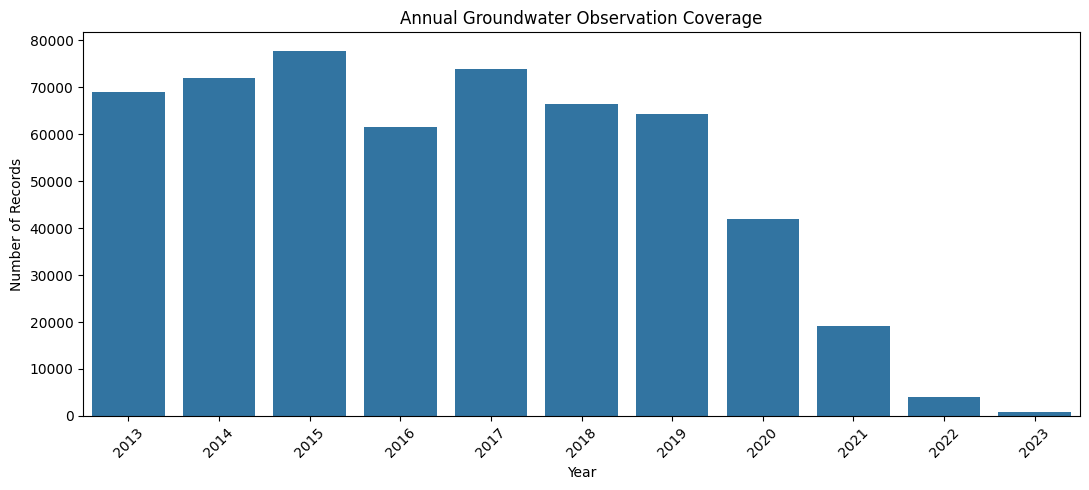

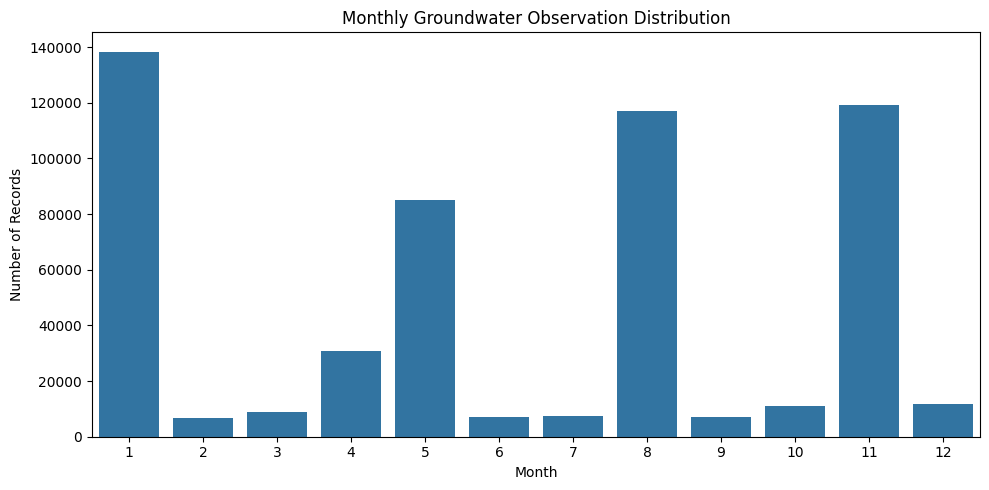

In [5]:

# Extract year and month for temporal analysis
df = (df
      .withColumn("year", F.year("date"))
      .withColumn("month", F.month("date")))

# Annual observation distribution
annual_summary = (
    df.groupBy("year")
      .agg(
          F.count("*").alias("total_records"),
          F.countDistinct("station_name").alias("station_names")
      )
      .orderBy("year")
)

print("Annual Observation Distribution:")
annual_summary.show(20, truncate=False)

# Monthly observation distribution
monthly_summary = (
    df.groupBy("month")
      .agg(F.count("*").alias("total_records"))
      .orderBy("month")
)

print("Monthly Observation Distribution:")
monthly_summary.show(12)

# Convert aggregated results for plotting
annual_pd = annual_summary.toPandas()
monthly_pd = monthly_summary.toPandas()

# Annual observations chart
plt.figure(figsize=(11, 5))
sns.barplot(data=annual_pd, x="year", y="total_records")
plt.title("Annual Groundwater Observation Coverage")
plt.xlabel("Year")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("annual_observation_coverage.png", dpi=300)
plt.show()

# Monthly observations chart
plt.figure(figsize=(10, 5))
sns.barplot(data=monthly_pd, x="month", y="total_records")
plt.title("Monthly Groundwater Observation Distribution")
plt.xlabel("Month")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.savefig("monthly_observation_distribution.png", dpi=300)
plt.show()


## 7. Station-Level Data Preparation

In [6]:

# Create a geographical identifier for each monitoring station
df = df.withColumn(
    "station_key",
    F.concat_ws(
        "_", "state_name", "district_name",
        "station_name", "latitude", "longitude"
    )
)

# Work with unique station-date combinations for gap analysis
station_dates = (
    df.select("station_key", "date")
      .distinct()
      .orderBy("station_key", "date")
)

# Calculate the gap between consecutive observation dates
date_window = Window.partitionBy("station_key").orderBy("date")

gap_data = (
    station_dates
    .withColumn("previous_date", F.lag("date").over(date_window))
    .withColumn(
        "gap_days",
        F.datediff("date", "previous_date")
    )
)

# Identify stations with more than two one-day gaps
station_quality = (
    gap_data.groupBy("station_key")
    .agg(
        F.sum(
            F.when(F.col("gap_days") == 1, 1).otherwise(0)
        ).alias("one_day_gaps")
    )
)

affected_stations = (
    station_quality
    .filter(F.col("one_day_gaps") > 2)
    .select("station_key")
)

# Retain unaffected stations for modelling candidates
candidate_df = df.join(
    affected_stations,
    on="station_key",
    how="left_anti"
)

print("Original records:", df.count())
print("Affected station identifiers:", affected_stations.count())
print("Candidate records:", candidate_df.count())
print(
    "Candidate station identifiers:",
    candidate_df.select("station_key").distinct().count()
)


Original records: 550850
Affected station identifiers: 23
Candidate records: 466392
Candidate station identifiers: 24215


## 8. Selecting Stations for Machine Learning

In [7]:

# Summarize historical coverage for each candidate station
station_summary = (
    candidate_df.groupBy("station_key")
    .agg(
        F.count("*").alias("total_records"),
        F.countDistinct("date").alias("distinct_dates"),
        F.countDistinct("year").alias("years_observed"),
        F.min("date").alias("first_observation"),
        F.max("date").alias("last_observation")
    )
)

# Select stations with sufficient historical coverage
eligible_stations = station_summary.filter(
    (F.col("total_records") >= 20) &
    (F.col("years_observed") >= 5)
)

# Create the modelling candidate dataset
selected_df = candidate_df.join(
    eligible_stations.select("station_key"),
    on="station_key",
    how="inner"
)

print("Eligible stations:", eligible_stations.count())
print("Selected records:", selected_df.count())

print("Historical coverage summary:")
eligible_stations.select(
    "total_records", "years_observed"
).describe().show()

print("Sample selected stations:")
eligible_stations.orderBy(
    F.desc("total_records")
).show(10, truncate=False)


Eligible stations: 13600
Selected records: 365045
Historical coverage summary:
+-------+------------------+-----------------+
|summary|     total_records|   years_observed|
+-------+------------------+-----------------+
|  count|             13600|            13600|
|   mean|26.841544117647057|8.548382352941177|
| stddev|3.4713912507085642|0.812169572230614|
|    min|                20|                5|
|    max|                39|               10|
+-------+------------------+-----------------+

Sample selected stations:
+-------------------------------------------------------+-------------+--------------+--------------+-----------------+----------------+
|station_key                                            |total_records|distinct_dates|years_observed|first_observation|last_observation|
+-------------------------------------------------------+-------------+--------------+--------------+-----------------+----------------+
|Telangana_Karimnagar_Buswapuram1_18.5625_79.92083      |39 

## Section 9 : Time-Series Feature Engineering

In [10]:


time_window = Window.partitionBy("station_key").orderBy("date", "id")

model_df = (
    selected_df
    .withColumn(
        "previous_level",
        F.lag("currentlevel", 1).over(time_window)
    )
    .withColumn(
        "previous_level_2",
        F.lag("currentlevel", 2).over(time_window)
    )
    .withColumn(
        "label",
        F.lead("currentlevel", 1).over(time_window)
    )
    .withColumn(
        "target_date",
        F.lead("date", 1).over(time_window)
    )
    # Use the current observation's month, not the future month
    .withColumn(
        "month_sin",
        F.sin(2 * 3.141592653589793 * F.month("date") / 12)
    )
    .withColumn(
        "month_cos",
        F.cos(2 * 3.141592653589793 * F.month("date") / 12)
    )
)

model_df = model_df.filter(
    F.col("previous_level").isNotNull() &
    F.col("previous_level_2").isNotNull() &
    F.col("label").isNotNull() &
    (F.col("target_date") <= F.lit("2021-12-31").cast("date"))
)

train_df = model_df.filter(
    F.col("target_date") < F.lit("2019-01-01").cast("date")
)

test_df = model_df.filter(
    (F.col("target_date") >= F.lit("2019-01-01").cast("date")) &
    (F.col("target_date") <= F.lit("2021-12-31").cast("date"))
)

print("Corrected modelling records:", model_df.count())
print("Training records:", train_df.count())
print("Testing records:", test_df.count())

model_df.select(
    "date", "currentlevel",
    "previous_level", "previous_level_2",
    "month_sin", "month_cos",
    "target_date", "label"
).show(10, truncate=False)


Corrected modelling records: 324242
Training records: 238168
Testing records: 86074
+----------+------------+--------------+----------------+-------------------+-------------------+-----------+-----+
|date      |currentlevel|previous_level|previous_level_2|month_sin          |month_cos          |target_date|label|
+----------+------------+--------------+----------------+-------------------+-------------------+-----------+-----+
|2013-11-04|1.02        |6.07          |2.5             |-0.5000000000000004|0.8660254037844384 |2014-01-04 |1.82 |
|2014-01-04|1.82        |1.02          |6.07            |0.49999999999999994|0.8660254037844387 |2014-05-14 |6.47 |
|2014-05-14|6.47        |1.82          |1.02            |0.49999999999999994|-0.8660254037844387|2014-08-24 |6.67 |
|2014-08-24|6.67        |6.47          |1.82            |-0.8660254037844384|-0.5000000000000004|2014-11-04 |6.97 |
|2014-11-04|6.97        |6.67          |6.47            |-0.5000000000000004|0.8660254037844384 |2015-01

#SECTION 10: FEATURE ENGINEERING & MODELLING

In [11]:

from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, RandomForestRegressor, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from math import pi

# 1. Create chronological window for each station
time_window = Window.partitionBy("station_key").orderBy("date", "id")

# 2. Generate prediction features and next-observation target
model_df = (
    selected_df
    .withColumn("previous_level", F.lag("currentlevel", 1).over(time_window))
    .withColumn("previous_level_2", F.lag("currentlevel", 2).over(time_window))
    .withColumn("label", F.lead("currentlevel", 1).over(time_window))
    .withColumn("target_date", F.lead("date", 1).over(time_window))

    # Seasonal features based on the current observation date
    .withColumn("month_sin", F.sin(2 * pi * F.month("date") / 12))
    .withColumn("month_cos", F.cos(2 * pi * F.month("date") / 12))
)

# 3. Remove rows without sufficient historical observations or target
model_df = model_df.filter(
    F.col("previous_level").isNotNull() &
    F.col("previous_level_2").isNotNull() &
    F.col("label").isNotNull() &
    F.col("target_date").isNotNull()
)

# 4. Restrict evaluation period to observations through 2021
model_df = model_df.filter(
    F.col("target_date") <= F.lit("2021-12-31").cast("date")
)

# 5. Chronological train-test split
train_df = model_df.filter(
    F.col("target_date") < F.lit("2019-01-01").cast("date")
)

test_df = model_df.filter(
    (F.col("target_date") >= F.lit("2019-01-01").cast("date")) &
    (F.col("target_date") <= F.lit("2021-12-31").cast("date"))
)

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

print("Training target date range:")
train_df.select(
    F.min("target_date"), F.max("target_date")
).show()

print("Testing target date range:")
test_df.select(
    F.min("target_date"), F.max("target_date")
).show()

# 6. Define model features
feature_columns = [
    "latitude",
    "longitude",
    "currentlevel",
    "previous_level",
    "previous_level_2",
    "month_sin",
    "month_cos"
]

# 7. Remove rows with missing feature or target values
train_df = train_df.dropna(subset=feature_columns + ["label"])
test_df = test_df.dropna(subset=feature_columns + ["label"])

# 8. Convert features into a vector
assembler = VectorAssembler(
    inputCols=feature_columns,
    outputCol="features",
    handleInvalid="skip"
)

train_data = assembler.transform(train_df).select("features", "label")
test_data = assembler.transform(test_df).select(
    "features", "label", "currentlevel"
)

# 9. Define evaluation metrics
rmse_evaluator = RegressionEvaluator(
    labelCol="label", predictionCol="prediction", metricName="rmse"
)

mae_evaluator = RegressionEvaluator(
    labelCol="label", predictionCol="prediction", metricName="mae"
)

r2_evaluator = RegressionEvaluator(
    labelCol="label", predictionCol="prediction", metricName="r2"
)

# 10. Train and evaluate Linear Regression
lr = LinearRegression(
    featuresCol="features",
    labelCol="label",
    maxIter=100
)

lr_model = lr.fit(train_data)
lr_predictions = lr_model.transform(test_data)

# 11. Train and evaluate Random Forest
rf = RandomForestRegressor(
    featuresCol="features",
    labelCol="label",
    numTrees=100,
    maxDepth=10,
    seed=42
)

rf_model = rf.fit(train_data)
rf_predictions = rf_model.transform(test_data)

# 12. Train and evaluate Gradient Boosted Trees
gbt = GBTRegressor(
    featuresCol="features",
    labelCol="label",
    maxIter=100,
    maxDepth=5,
    seed=42
)

gbt_model = gbt.fit(train_data)
gbt_predictions = gbt_model.transform(test_data)

# 13. Evaluate all models
results = []

for model_name, predictions in [
    ("Linear Regression", lr_predictions),
    ("Random Forest", rf_predictions),
    ("Gradient Boosted Trees", gbt_predictions)
]:
    rmse = rmse_evaluator.evaluate(predictions)
    mae = mae_evaluator.evaluate(predictions)
    r2 = r2_evaluator.evaluate(predictions)

    results.append((model_name, rmse, mae, r2))

# 14. Evaluate persistence baseline
# Baseline predicts the next reading using the current reading
baseline_predictions = test_data.withColumn(
    "prediction", F.col("currentlevel")
)

baseline_rmse = rmse_evaluator.evaluate(baseline_predictions)
baseline_mae = mae_evaluator.evaluate(baseline_predictions)
baseline_r2 = r2_evaluator.evaluate(baseline_predictions)

results.append((
    "Previous Observation Baseline",
    baseline_rmse,
    baseline_mae,
    baseline_r2
))

# 15. Display model comparison
results_df = spark.createDataFrame(
    results,
    ["Model", "RMSE", "MAE", "R2"]
)

print("FINAL MODEL PERFORMANCE COMPARISON")
results_df.orderBy("RMSE").show(truncate=False)

# 16. Check the prediction interval
print("Observation gap (days) between current and next readings:")
model_df.withColumn(
    "gap_days",
    F.datediff("target_date", "date")
).select(
    F.min("gap_days").alias("Minimum gap"),
    F.expr("percentile_approx(gap_days, 0.5)").alias("Median gap"),
    F.max("gap_days").alias("Maximum gap")
).show()

print("Section 10A completed successfully.")

Training records: 238168
Testing records: 86074
Training target date range:
+----------------+----------------+
|min(target_date)|max(target_date)|
+----------------+----------------+
|      2013-08-24|      2018-12-31|
+----------------+----------------+

Testing target date range:
+----------------+----------------+
|min(target_date)|max(target_date)|
+----------------+----------------+
|      2019-01-01|      2021-02-09|
+----------------+----------------+

FINAL MODEL PERFORMANCE COMPARISON
+-----------------------------+------------------+------------------+------------------+
|Model                        |RMSE              |MAE               |R2                |
+-----------------------------+------------------+------------------+------------------+
|Linear Regression            |3.4302346523439056|2.083583979197145 |0.8734284761956975|
|Random Forest                |3.9468309163801845|2.0853526753410216|0.8324341971005695|
|Gradient Boosted Trees       |3.956923059557469 |2.088

#Section 10B – Prediction Validation by Observation Gap

In [12]:

# Generate predictions while retaining dates
validation_df = assembler.transform(test_df)

validation_predictions = lr_model.transform(validation_df)

# Calculate the time gap between current and next observation
validation_predictions = validation_predictions.withColumn(
    "gap_days",
    F.datediff("target_date", "date")
)

# Group observations by prediction interval
validation_predictions = validation_predictions.withColumn(
    "gap_category",
    F.when(F.col("gap_days") <= 120, "Up to 120 days")
     .when(F.col("gap_days") <= 180, "121–180 days")
     .otherwise("Above 180 days")
)

# Calculate performance for each interval
gap_results = validation_predictions.groupBy("gap_category").agg(
    F.count("*").alias("records"),
    F.sqrt(F.avg(F.pow(F.col("label") - F.col("prediction"), 2))).alias("RMSE"),
    F.avg(F.abs(F.col("label") - F.col("prediction"))).alias("MAE")
)

print("MODEL PERFORMANCE BY OBSERVATION GAP")
gap_results.orderBy("gap_category").show(truncate=False)

# Display Linear Regression coefficients
print("LINEAR REGRESSION MODEL COEFFICIENTS")
for feature, coefficient in zip(feature_columns, lr_model.coefficients):
    print(f"{feature}: {coefficient:.6f}")

print("Intercept:", round(lr_model.intercept, 6))

MODEL PERFORMANCE BY OBSERVATION GAP
+--------------+-------+------------------+------------------+
|gap_category  |records|RMSE              |MAE               |
+--------------+-------+------------------+------------------+
|121–180 days  |13401  |3.4982303750496495|2.167173951713416 |
|Above 180 days|15136  |4.257795582245144 |2.8020031086115007|
|Up to 120 days|57537  |3.1596010508215517|1.8751236638434299|
+--------------+-------+------------------+------------------+

LINEAR REGRESSION MODEL COEFFICIENTS
latitude: 0.019516
longitude: -0.027073
currentlevel: 0.436696
previous_level: 0.225675
previous_level_2: 0.306396
month_sin: 0.025751
month_cos: 1.526975
Intercept: 1.861167


#Section 11 – Model Visualization

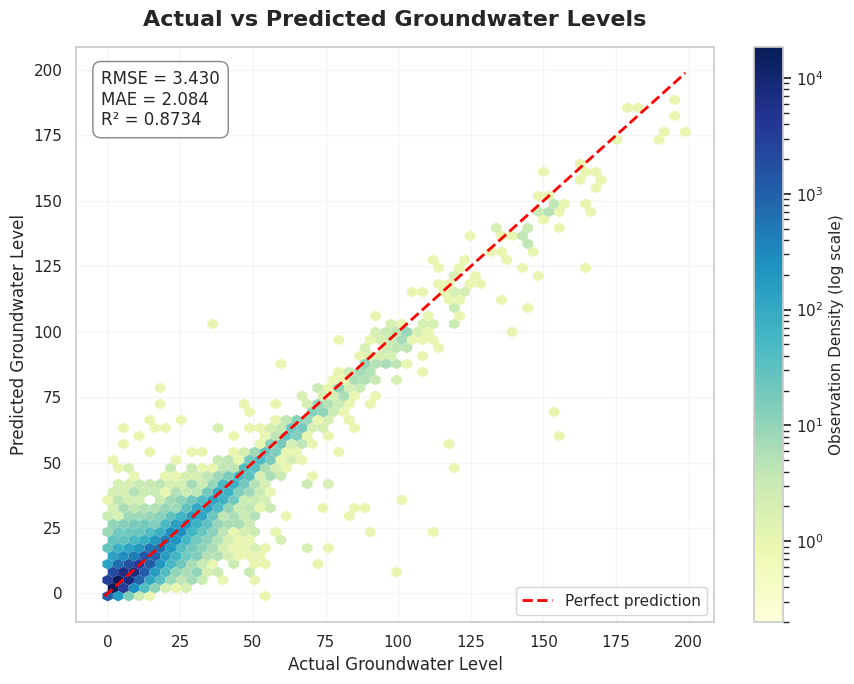

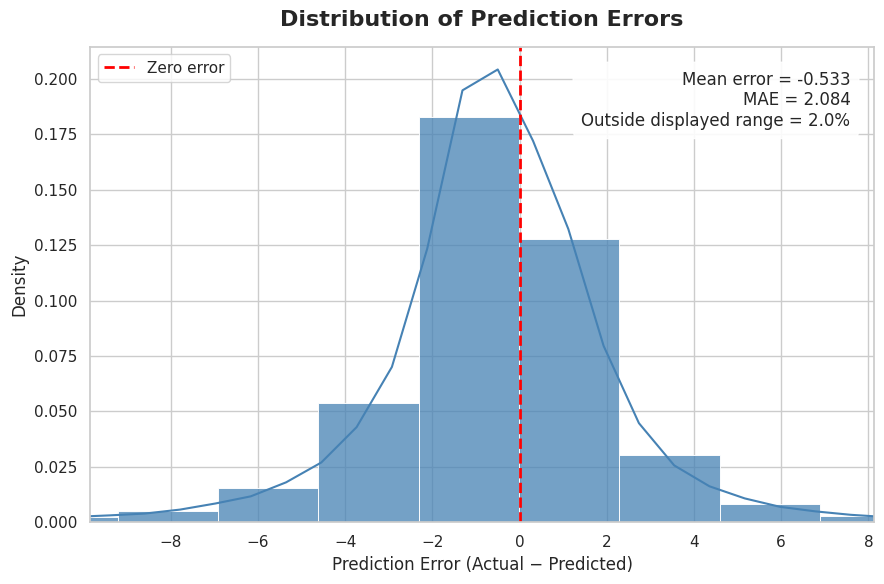

Final visualizations generated successfully.
Total test observations: 86074
RMSE: 3.4302
MAE: 2.0836
R2: 0.8734
Percentage outside error plot range: 2.0


In [17]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Convert model predictions to Pandas
plot_df = lr_predictions.select(
    "label", "prediction"
).toPandas().dropna()

plot_df["error"] = plot_df["label"] - plot_df["prediction"]

# Calculate performance metrics
rmse = np.sqrt(np.mean(plot_df["error"] ** 2))
mae = np.mean(np.abs(plot_df["error"]))

# Consistent professional plotting style
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["font.family"] = "DejaVu Sans"

# ==========================================
# IMPROVED CHART 1: ACTUAL VS PREDICTED
# ==========================================

fig, ax = plt.subplots(figsize=(9, 7))

hb = ax.hexbin(
    plot_df["label"],
    plot_df["prediction"],
    gridsize=55,
    cmap="YlGnBu",
    mincnt=1,
    bins="log",
    vmin=0.2,
    linewidths=0.1,
    edgecolors="none"

)

# Perfect prediction reference line
min_val = min(plot_df["label"].min(), plot_df["prediction"].min())
max_val = max(plot_df["label"].max(), plot_df["prediction"].max())

ax.plot(
    [min_val, max_val],
    [min_val, max_val],
    color="red",
    linestyle="--",
    linewidth=2,
    label="Perfect prediction"
)

# Model metrics
ax.text(
    0.04, 0.96,
    f"RMSE = {rmse:.3f}\nMAE = {mae:.3f}\nR² = 0.8734",
    transform=ax.transAxes,
    verticalalignment="top",
    fontsize=12,
    bbox=dict(
        boxstyle="round,pad=0.5",
        facecolor="white",
        edgecolor="gray",
        alpha=0.95
    )
)

ax.set_title(
    "Actual vs Predicted Groundwater Levels",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Actual Groundwater Level", fontsize=12)
ax.set_ylabel("Predicted Groundwater Level", fontsize=12)

cbar = fig.colorbar(hb, ax=ax)
cbar.set_label("Observation Density (log scale)", fontsize=11)

ax.legend(loc="lower right")
ax.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Actual_vs_Predicted_Final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



# ==========================================
# CHART 2: PREDICTION ERROR DISTRIBUTION
# ==========================================

fig, ax = plt.subplots(figsize=(9, 6))

# Display central 98% to make the main distribution readable
lower = plot_df["error"].quantile(0.01)
upper = plot_df["error"].quantile(0.99)

sns.histplot(
    plot_df["error"],
    bins=70,
    kde=True,
    stat="density",
    color="steelblue",
    edgecolor="white",
    alpha=0.75,
    ax=ax
)

# Zero-error reference
ax.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Zero error"
)

ax.set_xlim(lower, upper)

# Calculate proportion outside displayed range
outside = (
    (plot_df["error"] < lower) |
    (plot_df["error"] > upper)
).mean() * 100

ax.text(
    0.97, 0.95,
    f"Mean error = {plot_df['error'].mean():.3f}\n"
    f"MAE = {mae:.3f}\n"
    f"Outside displayed range = {outside:.1f}%",
    transform=ax.transAxes,
    ha="right",
    va="top",
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", alpha=0.9)
)

ax.set_title(
    "Distribution of Prediction Errors",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Prediction Error (Actual − Predicted)", fontsize=12)
ax.set_ylabel("Density", fontsize=12)

ax.legend()
plt.tight_layout()

plt.savefig(
    "Prediction_Error_Distribution_Final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final visualizations generated successfully.")
print("Total test observations:", len(plot_df))
print("RMSE:", round(rmse, 4))
print("MAE:", round(mae, 4))
print("R2: 0.8734")
print("Percentage outside error plot range:", round(outside, 2))

Section 12 – Spatial Analysis of Groundwater Levels Across India

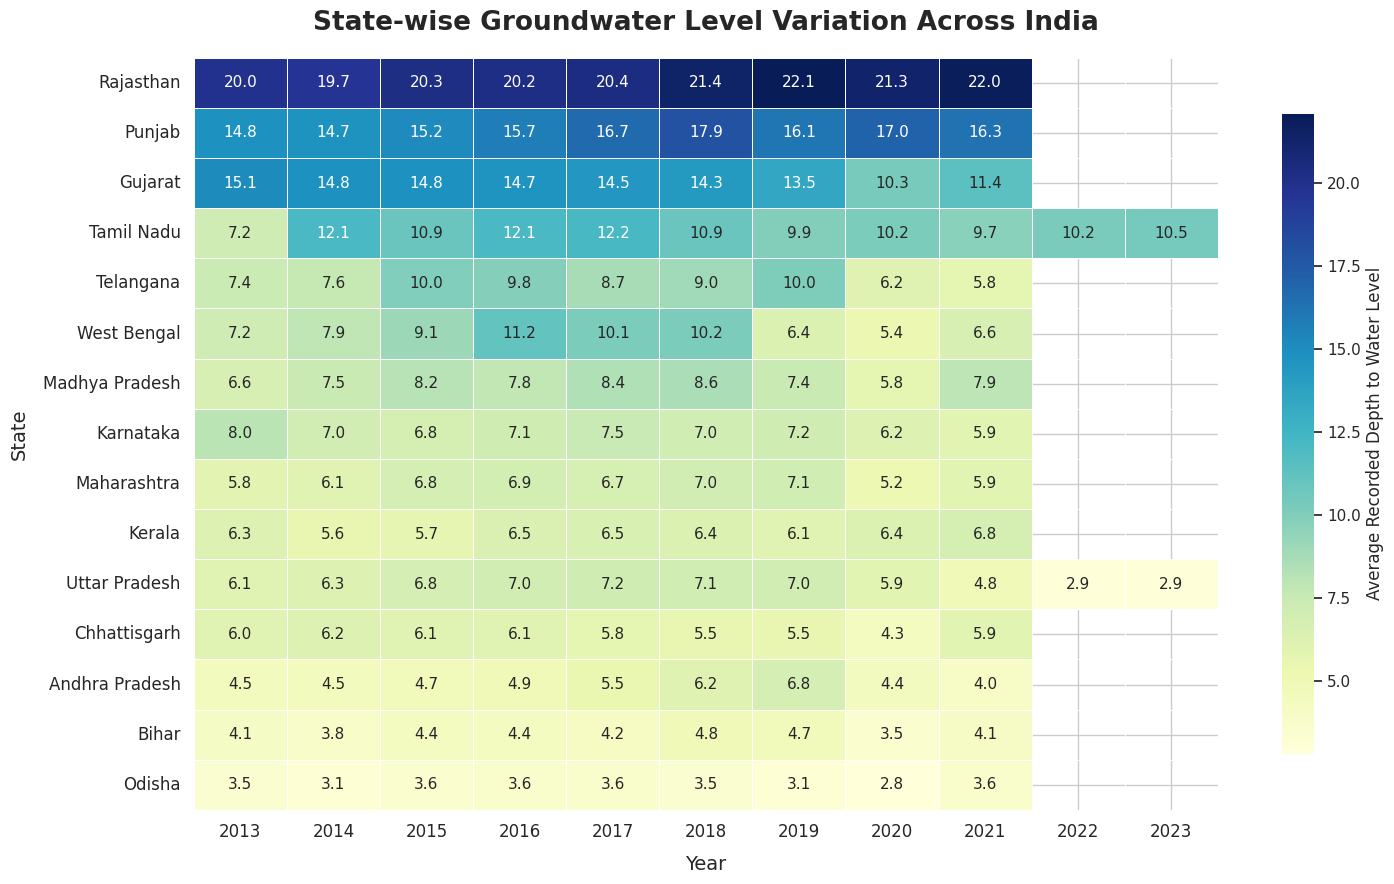

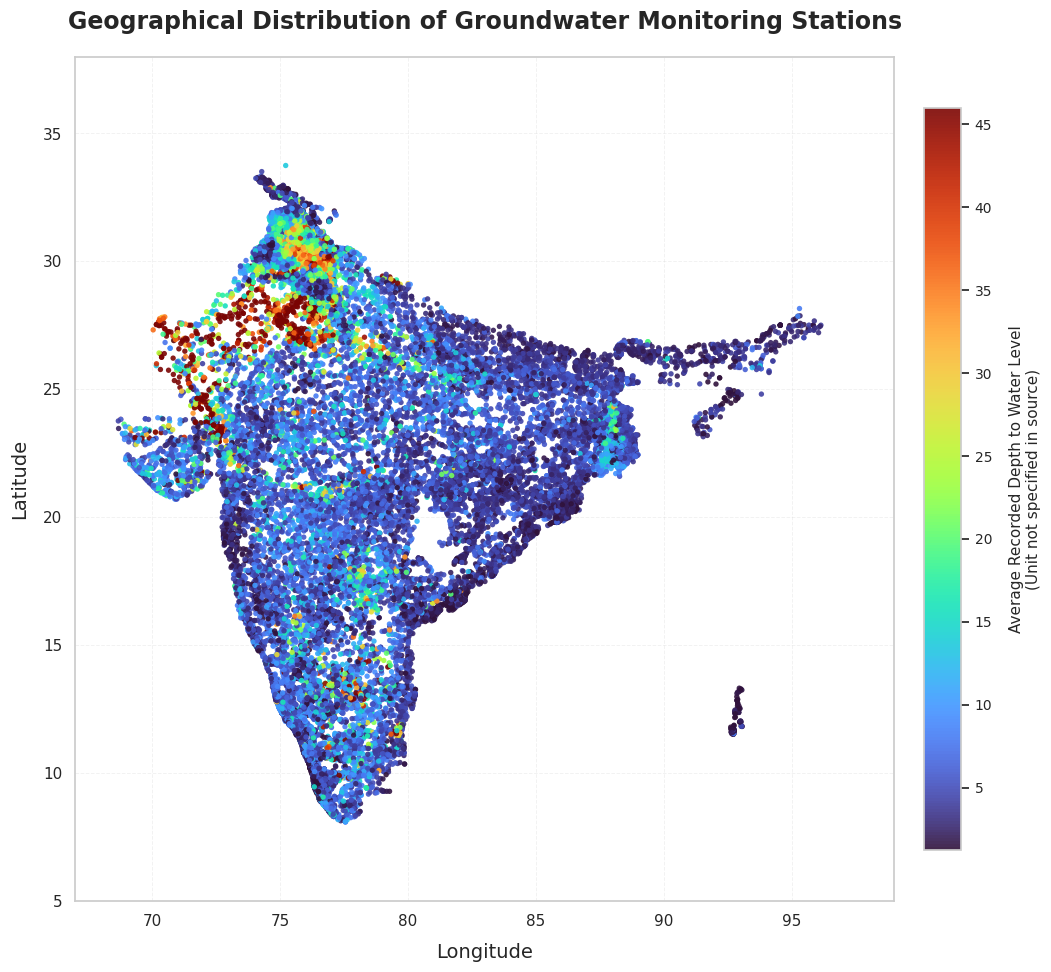

SPATIAL ANALYSIS COMPLETED
Valid station identifiers: 24238
States in heatmap: 15
Years: [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
Map colour scale: 1.25 to 45.98
Final charts saved successfully.


In [20]:


import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from pyspark.sql import functions as F

sns.set_theme(style="whitegrid", context="notebook")

# Use original dataset for spatial analysis
spatial_df = df.filter(
    F.col("latitude").isNotNull() &
    F.col("longitude").isNotNull() &
    F.col("currentlevel").isNotNull()
)

# =====================================================
# CHART 1: STATE-WISE GROUNDWATER HEATMAP
# =====================================================

state_year = spatial_df.groupBy(
    "state_name", "year"
).agg(
    F.avg("currentlevel").alias("avg_level"),
    F.count("*").alias("records")
)

# Select top 15 states by observation count
top_states = (
    spatial_df.groupBy("state_name")
    .count()
    .orderBy(F.desc("count"))
    .limit(15)
    .select("state_name")
)

heatmap_df = (
    state_year.join(top_states, "state_name", "inner")
    .toPandas()
)

heatmap_data = heatmap_df.pivot(
    index="state_name",
    columns="year",
    values="avg_level"
)

record_data = heatmap_df.pivot(
    index="state_name",
    columns="year",
    values="records"
)

# Mask state-year combinations with fewer than 30 records
heatmap_data = heatmap_data.where(record_data >= 30)

# Sort states by average recorded level
state_order = (
    heatmap_df.groupby("state_name")["avg_level"]
    .mean()
    .sort_values(ascending=False)
    .index
)

heatmap_data = heatmap_data.reindex(state_order)

# Slightly softer heatmap colours
fig, ax = plt.subplots(figsize=(15, 9))

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    annot=True,
    fmt=".1f",
    linewidths=0.6,
    linecolor="white",
    annot_kws={"size": 11},
    cbar_kws={
        "label": "Average Recorded Depth to Water Level",
        "shrink": 0.85
    },
    ax=ax
)

ax.set_title(
    "State-wise Groundwater Level Variation Across India",
    fontsize=19,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Year", fontsize=14, labelpad=10)
ax.set_ylabel("State", fontsize=14, labelpad=10)

ax.tick_params(axis="x", labelsize=12, rotation=0)
ax.tick_params(axis="y", labelsize=12, rotation=0)

plt.tight_layout()

plt.savefig(
    "State_Wise_Groundwater_Heatmap_Final.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# =====================================================
# CHART 2: INDIA GEOGRAPHICAL DISTRIBUTION MAP
# =====================================================

station_map = spatial_df.groupBy(
    "station_key"
).agg(
    F.avg("latitude").alias("latitude"),
    F.avg("longitude").alias("longitude"),
    F.avg("currentlevel").alias("avg_level"),
    F.count("*").alias("observations")
)

map_df = station_map.toPandas()

# Keep valid coordinates within India's approximate extent
map_df = map_df[
    map_df["latitude"].between(6, 38) &
    map_df["longitude"].between(68, 98)
].dropna(
    subset=["latitude", "longitude", "avg_level"]
)

# Percentile-based colour scaling
vmin = map_df["avg_level"].quantile(0.02)
vmax = map_df["avg_level"].quantile(0.98)

fig, ax = plt.subplots(figsize=(11, 10))

scatter = ax.scatter(
    map_df["longitude"],
    map_df["latitude"],
    c=map_df["avg_level"],
    cmap="turbo",
    vmin=vmin,
    vmax=vmax,
    s=15,
    alpha=0.9,
    edgecolors="none",
    rasterized=True
)

ax.set_xlim(67, 99)
ax.set_ylim(5, 38)

ax.set_title(
    "Geographical Distribution of Groundwater Monitoring Stations",
    fontsize=17,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Longitude", fontsize=14, labelpad=10)
ax.set_ylabel("Latitude", fontsize=14, labelpad=10)

# Clearly labelled colour bar
cbar = fig.colorbar(
    scatter,
    ax=ax,
    shrink=0.82,
    pad=0.03
)

cbar.set_label(
    "Average Recorded Depth to Water Level\n(Unit not specified in source)",
    fontsize=11,
    labelpad=12
)

cbar.ax.tick_params(labelsize=10)

ax.tick_params(axis="both", labelsize=11)
ax.grid(alpha=0.25, linestyle="--", linewidth=0.7)
ax.set_aspect("equal", adjustable="box")

plt.tight_layout()

plt.savefig(
    "India_Groundwater_Spatial_Distribution_Final.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# =====================================================
# SPATIAL ANALYSIS SUMMARY
# =====================================================

print("SPATIAL ANALYSIS COMPLETED")

print("Valid station identifiers:", len(map_df))
print("States in heatmap:", heatmap_data.shape[0])
print("Years:", list(heatmap_data.columns))

print("Map colour scale:", round(vmin, 2), "to", round(vmax, 2))

print("Final charts saved successfully.")

### 13. Results and Model Evaluation

The forecasting models were evaluated using a chronological train-test split. Data with target dates before 2019 were used for training, while observations from 2019 onward were used for testing.

Linear Regression achieved the best performance among the evaluated models, outperforming Random Forest, Gradient Boosted Trees and the previous-observation baseline.

The model achieved an RMSE of 3.4302, MAE of 2.0836 and R² of 0.8734 on 86,074 test observations.

Validation by observation gap showed that prediction errors increased as the interval between consecutive observations became longer. This highlights the influence of irregular monitoring intervals on forecasting performance.

FINAL MODEL PERFORMANCE


,Model,RMSE,MAE,R2
0,Linear Regression,3.4302,2.0836,0.8734
1,Random Forest,3.9468,2.0854,0.8324
2,Gradient Boosted Trees,3.9569,2.0884,0.8316
3,Previous Observation Baseline,4.0419,2.2667,0.8243


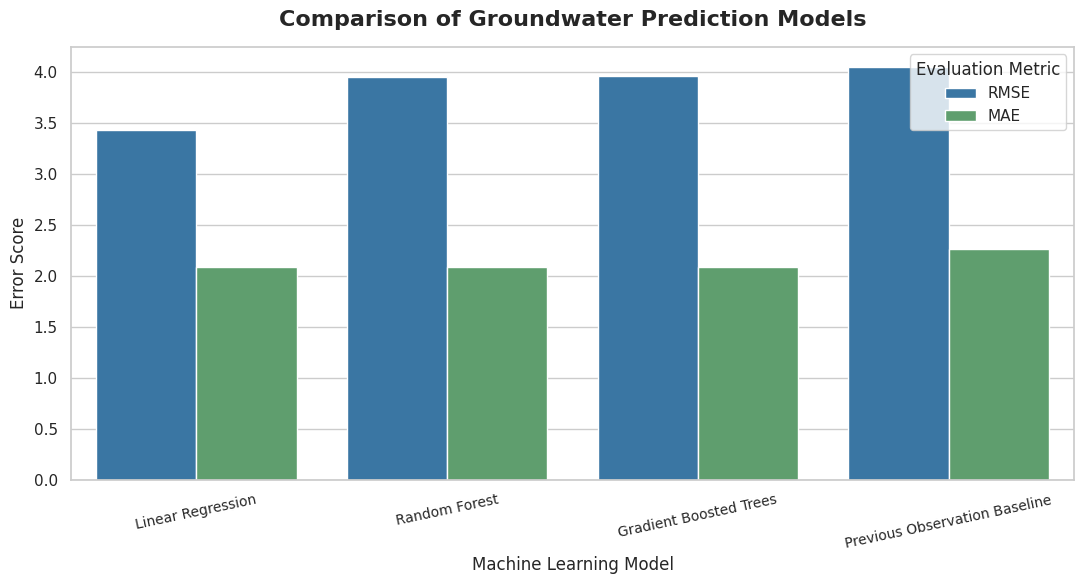

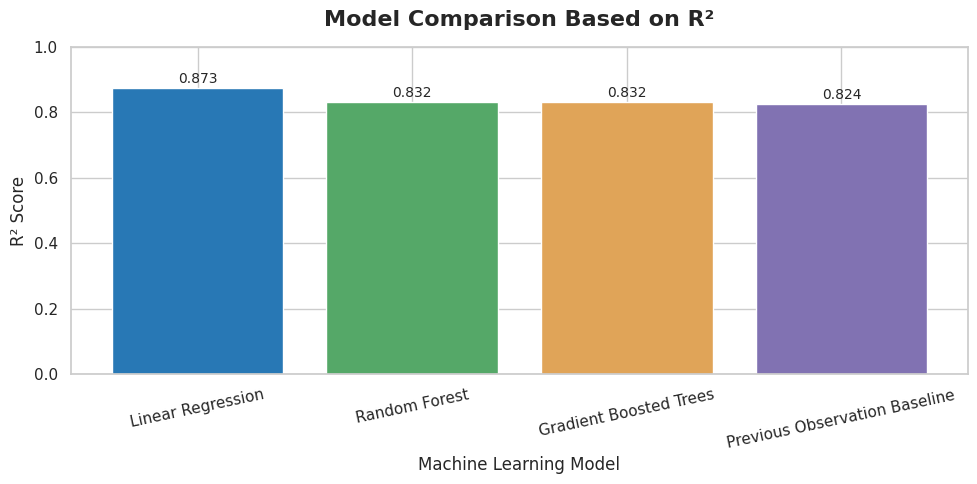

MODEL PERFORMANCE BY OBSERVATION GAP


,gap_category,records,RMSE,MAE
0,Above 180 days,15136,4.258,2.802
1,Up to 120 days,57537,3.160,1.875
2,121–180 days,13401,3.498,2.167


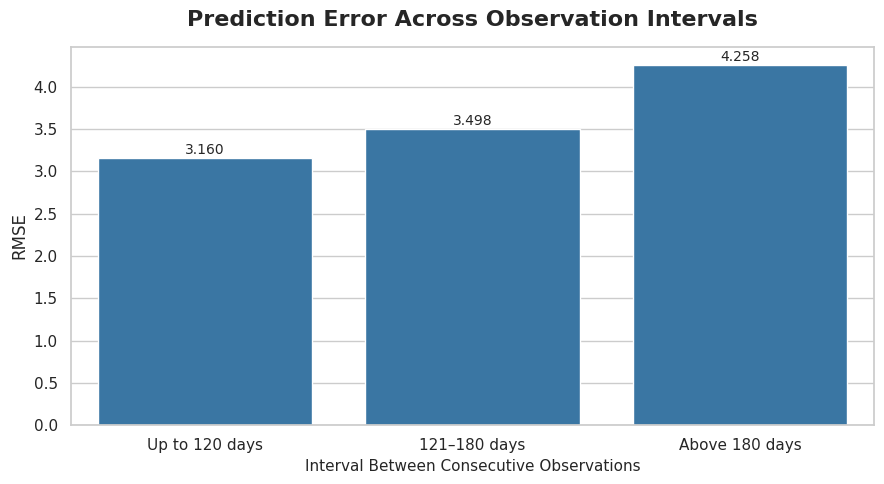


FINAL RESEARCH SUMMARY
------------------------------------
Best model: Linear Regression
RMSE: 3.4302
MAE: 2.0836
R2: 0.8734
Training records: 238168
Testing records: 86074
Training target period: Before 2019
Testing target period: 2019 onwards, through February 2021

Section 13 completed successfully.


In [21]:
# =====================================================
# SECTION 13: FINAL RESULTS AND MODEL EVALUATION
# =====================================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid", context="notebook")

# -----------------------------------------------------
# 1. MODEL PERFORMANCE COMPARISON TABLE
# -----------------------------------------------------

results_pd = results_df.toPandas()

# Round metrics for presentation
results_display = results_pd.copy()

for col in ["RMSE", "MAE", "R2"]:
    results_display[col] = results_display[col].round(4)

print("FINAL MODEL PERFORMANCE")
display(results_display.sort_values("RMSE").reset_index(drop=True))

# -----------------------------------------------------
# 2. MODEL COMPARISON CHART: RMSE AND MAE
# -----------------------------------------------------

comparison_pd = results_pd.melt(
    id_vars="Model",
    value_vars=["RMSE", "MAE"],
    var_name="Metric",
    value_name="Score"
)

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=comparison_pd,
    x="Model",
    y="Score",
    hue="Metric",
    palette=["#2878B5", "#55A868"],
    ax=ax
)

ax.set_title(
    "Comparison of Groundwater Prediction Models",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Machine Learning Model", fontsize=12)
ax.set_ylabel("Error Score", fontsize=12)
ax.tick_params(axis="x", rotation=12, labelsize=10)
ax.legend(title="Evaluation Metric")

plt.tight_layout()

plt.savefig(
    "Final_Model_Performance_Comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# -----------------------------------------------------
# 3. MODEL R-SQUARED COMPARISON
# -----------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

r2_pd = results_pd.sort_values("R2", ascending=False)

bars = ax.bar(
    r2_pd["Model"],
    r2_pd["R2"],
    color=["#2878B5", "#55A868", "#E0A458", "#8172B2"]
)

ax.set_title(
    "Model Comparison Based on R²",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Machine Learning Model", fontsize=12)
ax.set_ylabel("R² Score", fontsize=12)
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=12)

for bar, value in zip(bars, r2_pd["R2"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.015,
        f"{value:.3f}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    "Final_Model_R2_Comparison.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# -----------------------------------------------------
# 4. OBSERVATION GAP VALIDATION TABLE
# -----------------------------------------------------

gap_pd = gap_results.toPandas()

print("MODEL PERFORMANCE BY OBSERVATION GAP")

gap_pd["RMSE"] = gap_pd["RMSE"].round(3)
gap_pd["MAE"] = gap_pd["MAE"].round(3)

display(gap_pd)


# -----------------------------------------------------
# 5. OBSERVATION GAP VALIDATION CHART
# -----------------------------------------------------

gap_order = [
    "Up to 120 days",
    "121–180 days",
    "Above 180 days"
]

gap_pd["gap_category"] = pd.Categorical(
    gap_pd["gap_category"],
    categories=gap_order,
    ordered=True
)

gap_pd = gap_pd.sort_values("gap_category")

fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(
    data=gap_pd,
    x="gap_category",
    y="RMSE",
    color="#2878B5",
    ax=ax
)

ax.set_title(
    "Prediction Error Across Observation Intervals",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Interval Between Consecutive Observations", fontsize=11)
ax.set_ylabel("RMSE", fontsize=12)

for i, row in enumerate(gap_pd.itertuples()):
    ax.text(
        i,
        row.RMSE + 0.05,
        f"{row.RMSE:.3f}",
        ha="center",
        fontsize=10
    )

plt.tight_layout()

plt.savefig(
    "Observation_Gap_Validation.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


# -----------------------------------------------------
# 6. FINAL RESEARCH SUMMARY
# -----------------------------------------------------

best_model = results_pd.loc[results_pd["RMSE"].idxmin()]

print("\nFINAL RESEARCH SUMMARY")
print("------------------------------------")
print("Best model:", best_model["Model"])
print("RMSE:", round(best_model["RMSE"], 4))
print("MAE:", round(best_model["MAE"], 4))
print("R2:", round(best_model["R2"], 4))

print("Training records:", train_df.count())
print("Testing records:", test_df.count())

print("Training target period: Before 2019")
print("Testing target period: 2019 onwards, through February 2021")

print("\nSection 13 completed successfully.")

### Key Findings

- Linear Regression achieved the best overall performance, with an RMSE of 3.4302, MAE of 2.0836 and R² of 0.8734.
- It outperformed the previous-observation baseline, reducing RMSE by approximately 15.1%.
- Random Forest and Gradient Boosted Trees achieved lower performance than Linear Regression on the test dataset.
- Prediction accuracy varied with observation intervals. The lowest RMSE (3.160) was observed for gaps up to 120 days, while gaps exceeding 180 days had an RMSE of 4.258.
- The findings indicate that historical groundwater-level observations and seasonal information can support next-observation prediction, although irregular monitoring intervals remain an important limitation.

### 14. Conclusion

This study developed a PySpark-based groundwater analytics and next-observation forecasting workflow using CGWB groundwater-level records across India.

Among the evaluated models, Linear Regression achieved the best performance, with an RMSE of 3.4302, MAE of 2.0836 and R² of 0.8734. It outperformed the previous-observation baseline, demonstrating the usefulness of historical groundwater observations and seasonal features for predicting subsequent readings.

The spatial analysis revealed geographical variation in recorded groundwater levels across states and monitoring locations. Observation-gap validation further showed that prediction accuracy decreases as the interval between consecutive observations increases.

### Limitations

- Monitoring coverage varies considerably across years and geographical regions.
- Observation intervals are irregular and do not represent a fixed forecasting horizon.
- The station identifiers are constructed from available location and station fields and may not represent unique physical wells.
- The model evaluation focuses on previously observed stations; performance on entirely unseen stations has not been established.
- The measurement unit and sign convention require confirmation from the original source documentation.
- The selected station-history and data-quality filters may affect the representativeness of the modelling dataset.

### 15. References

1. Central Ground Water Board (CGWB), *Changes in Depth to Water Level*, India Data Portal. Available: https://ckandev.indiadataportal.com/dataset/groundwater/resource/580a8f6e-3d86-4ca7-ac7d-cd5df12b443c

2. Apache Software Foundation, *Apache Spark 4.0.5 – Machine Learning Library (MLlib) Guide*. Available: https://spark.apache.org/docs/4.0.5/ml-guide.html

3. Apache Software Foundation, *PySpark Documentation*. Available: https://spark.apache.org/docs/4.0.5/api/python/

4. Central Ground Water Board (CGWB), *Ground Water Level Monitoring*. Available: https://cgwb.gov.in/hi/ground-water-level-monitoring

### 16. Acknowledgement

I sincerely express my gratitude to **Chanakya University** for providing the academic environment, guidance and opportunity to undertake this research project and present its findings.

I also acknowledge the **Central Ground Water Board (CGWB)** and the **India Data Portal** for making the groundwater dataset available for research and analysis.

Finally, I thank everyone who contributed directly or indirectly to the completion of this work.